# Class 20: Who Got In — Solution Notebook

**Instructor copy.** Reproduces every number and figure on the handout and reveal slides, then goes one step further: it splits the 400 applicants into **honors** (admitted) and **non-honors** (not admitted) students and fits a regression line to each group, for both admission rules.

The data are synthetic (`data/applicants.csv`, generated by `data/make_admissions.py`, seed 2026). Nothing here describes a real admissions process.

In [1]:
import numpy as np
from datascience import *
import matplotlib.pyplot as plt
%matplotlib inline
print("Ready!")

Ready!


### Helper functions
The same four from Classes 17–18.

In [2]:
def standard_units(any_numbers):
    "Convert any array of numbers to standard units."
    return (any_numbers - np.mean(any_numbers)) / np.std(any_numbers)

def correlation(t, label_x, label_y):
    return np.mean(standard_units(t.column(label_x)) * standard_units(t.column(label_y)))

def slope(t, label_x, label_y):
    r = correlation(t, label_x, label_y)
    return r * np.std(t.column(label_y)) / np.std(t.column(label_x))

def intercept(t, label_x, label_y):
    return np.mean(t.column(label_y)) - slope(t, label_x, label_y) * np.mean(t.column(label_x))

---
## Part 1. All 400 Applicants

In [3]:
applicants = Table.read_table("./data/applicants.csv")

r_all = correlation(applicants, 'HS_GPA', 'SAT')
m_all = slope(applicants, 'HS_GPA', 'SAT')
b_all = intercept(applicants, 'HS_GPA', 'SAT')

print("Applicants:", applicants.num_rows)
print(f"r = {r_all:.2f}")
print(f"SAT = {m_all:.1f} * GPA + {b_all:.1f}")
applicants.show(5)

Applicants: 400
r = 0.41
SAT = 201.4 * GPA + 490.7


HS_GPA,SAT
3.06,890
3.37,1010
2.73,1050
3.72,1320
3.49,1420


### A plotting function for the split
Draws honors and non-honors students in different colors, the admission cutoff, and three regression lines: one for all applicants, one for each group. Each group's line is drawn only across that group's own GPA range.

In [4]:
def regression_segment(t, color, style, label):
    "Draw the regression line of SAT on GPA for table t, across t's GPA range."
    m = slope(t, 'HS_GPA', 'SAT')
    b = intercept(t, 'HS_GPA', 'SAT')
    r = correlation(t, 'HS_GPA', 'SAT')
    gpa_ends = np.array([min(t.column('HS_GPA')), max(t.column('HS_GPA'))])
    plt.plot(gpa_ends, m * gpa_ends + b, color=color, linestyle=style, linewidth=2.5,
             label=f"{label}: r = {r:+.2f}, slope = {m:+.0f} SAT pts per GPA pt")

def plot_split(honors, non_honors, title):
    plt.figure(figsize=(9, 6))
    plt.scatter(non_honors.column('HS_GPA'), non_honors.column('SAT'),
                color='silver', s=14, label=f"Non-honors (n = {non_honors.num_rows})")
    plt.scatter(honors.column('HS_GPA'), honors.column('SAT'),
                color='#9E1B34', s=16, alpha=0.6, label=f"Honors (n = {honors.num_rows})")
    regression_segment(applicants, 'black', '--', "All applicants")
    regression_segment(non_honors, 'dimgray', '-', "Non-honors")
    regression_segment(honors, '#9E1B34', '-', "Honors")
    plt.xlim(2.3, 4.08)
    plt.ylim(650, 1650)
    plt.xlabel('High school GPA')
    plt.ylabel('SAT score')
    plt.title(title)
    plt.grid(True, alpha=0.3)

---
## Part 2. Program A — Admit the Top 30% on a Combined Index

Combined score = GPA in standard units + SAT in standard units. The 120th-highest score is the cutoff.

In [5]:
gpa_su = standard_units(applicants.column('HS_GPA'))
sat_su = standard_units(applicants.column('SAT'))
applicants = applicants.with_column('Index', gpa_su + sat_su)

sorted_index = np.sort(applicants.column('Index'))[::-1]   # largest first
cutoff_A = sorted_index.item(119)                          # the 120th largest

honors_A = applicants.where('Index', are.above_or_equal_to(cutoff_A))
non_honors_A = applicants.where('Index', are.below(cutoff_A))

print(f"Cutoff (standard units): {cutoff_A:.3f}")
print("Honors:", honors_A.num_rows, "   Non-honors:", non_honors_A.num_rows)

Cutoff (standard units): 0.956
Honors: 120    Non-honors: 280


The cutoff is the line GPA$_{su}$ + SAT$_{su}$ = cutoff. Converting back to original units gives the line through the two stars on the handout.

In [6]:
mean_gpa = np.mean(applicants.column('HS_GPA'))
sd_gpa = np.std(applicants.column('HS_GPA'))
mean_sat = np.mean(applicants.column('SAT'))
sd_sat = np.std(applicants.column('SAT'))

def cutoff_sat(gpa):
    "SAT score on the Program A cutoff line, for a given GPA."
    return mean_sat + sd_sat * (cutoff_A - (gpa - mean_gpa) / sd_gpa)

print(f"Star 1: GPA 3.00, SAT {cutoff_sat(3.00):.0f}")
print(f"Star 2: GPA 4.00, SAT {cutoff_sat(4.00):.0f}")

Star 1: GPA 3.00, SAT 1458
Star 2: GPA 4.00, SAT 962


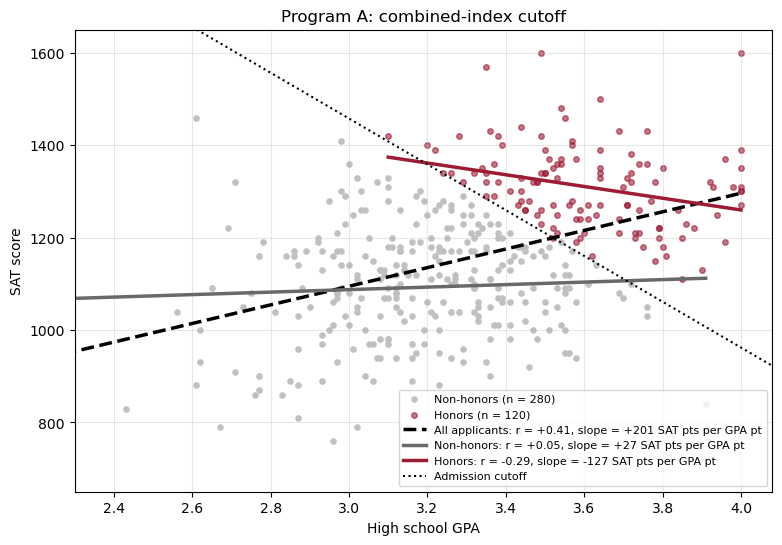

In [7]:
plot_split(honors_A, non_honors_A, "Program A: combined-index cutoff")
gpa_grid = np.linspace(2.3, 4.08, 50)
plt.plot(gpa_grid, cutoff_sat(gpa_grid), color='black', linestyle=':', linewidth=1.5, label='Admission cutoff')
plt.legend(fontsize=8, loc='lower right')
plt.show()

> **Handout Q1.** The admitted region is above and to the right of the line. It slopes downward because the rule is compensatory: a lower GPA can be made up with a higher SAT, and vice versa.
>
> **Handout Q2.** Key: **weakly negative** (r = −0.29 for the 120 honors students).
>
> **Handout Q3.** The trade-off comes from the selection rule, not from the students. Among all applicants the relationship is positive (r = +0.41). To clear a downward-sloping line, anyone low on one score must be high on the other, so the admitted group forms a band tilted along the cutoff. The applicants who would show the positive relationship — low on both — are exactly the ones the dean never sees.
>
> **Beyond the handout: the non-honors side is distorted too.** The 280 rejected students have r = +0.05, nearly zero. The cut removes the high-on-both corner from this group, which flattens the relationship. Neither group, by itself, recovers the +0.41 in the full pool.

---
## Part 3. Program B — Admit the Top 30% by GPA Alone

In [8]:
sorted_gpa = np.sort(applicants.column('HS_GPA'))[::-1]
cutoff_B = sorted_gpa.item(119)

honors_B = applicants.where('HS_GPA', are.above_or_equal_to(cutoff_B))
non_honors_B = applicants.where('HS_GPA', are.below(cutoff_B))

print(f"GPA cutoff: {cutoff_B:.2f}")
print("Honors:", honors_B.num_rows, "   Non-honors:", non_honors_B.num_rows)
print("(More than 120 honors students because several applicants are tied at the cutoff GPA.)")

GPA cutoff: 3.48
Honors: 123    Non-honors: 277
(More than 120 honors students because several applicants are tied at the cutoff GPA.)


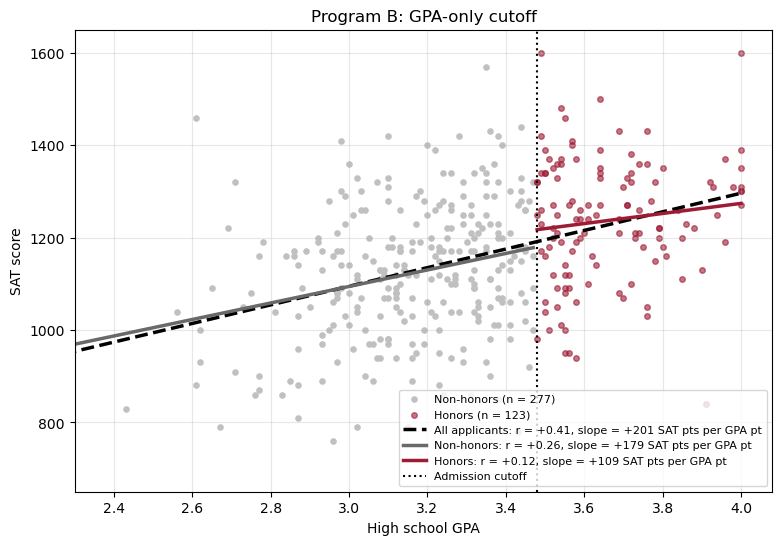

In [9]:
plot_split(honors_B, non_honors_B, "Program B: GPA-only cutoff")
plt.axvline(cutoff_B, color='black', linestyle=':', linewidth=1.5, label='Admission cutoff')
plt.legend(fontsize=8, loc='lower right')
plt.show()

> **Handout Q4.** Positive but smaller than +0.41: r = +0.12 for the 123 honors students. Cutting on GPA alone narrows GPA's range, which weakens r (restriction of range), but a vertical cutoff doesn't force any trade-off, so the sign does not flip. The honors and non-honors lines both still slope upward.

---
## Part 4. Side by Side

In [10]:
groups = make_array('All applicants', 'Program A honors', 'Program A non-honors',
                    'Program B honors', 'Program B non-honors')
tables = [applicants, honors_A, non_honors_A, honors_B, non_honors_B]

sizes = make_array()
r_values = make_array()
slopes = make_array()
for t in tables:
    sizes = np.append(sizes, t.num_rows)
    r_values = np.append(r_values, np.round(correlation(t, 'HS_GPA', 'SAT'), 2))
    slopes = np.append(slopes, np.round(slope(t, 'HS_GPA', 'SAT'), 1))

summary = Table().with_columns('Group', groups, 'n', sizes, 'r', r_values,
                               'Slope (SAT pts per GPA pt)', slopes)
summary.show()

Group,n,r,Slope (SAT pts per GPA pt)
All applicants,400,0.41,201.4
Program A honors,120,-0.29,-127
Program A non-honors,280,0.05,27
Program B honors,123,0.12,109.2
Program B non-honors,277,0.26,178.6


Same 400 applicants, five different answers to "how are GPA and SAT related?" Only the first row describes the population; every other row describes a selection rule as much as it describes students.

> **Handout Q5 — sample answers.** "SAT scores don't predict college grades" (when measured only among admitted students). "Students with more extracurriculars had lower GPAs" (if both counted toward admission). "Our study habits must work" (with no data on non-admitted students who used the same habits).